# Exploración de biodiversidad con la API pública de GBIF

En este cuaderno consultamos la API pública de **GBIF** (*Global Biodiversity Information Facility*) para descargar, validar, analizar y cartografiar registros de presencia de *Canis lupus* en España.


La documentación oficial de la API está en <https://www.gbif.org/developer/summary>. Las especificaciones OpenAPI 3.1 de cada sub-API se encuentran en <https://techdocs.gbif.org/en/openapi/>.

| Sub-API | Documentación | Endpoints usados |
|---|---|---|
| **Occurrence** | [techdocs.gbif.org/en/openapi/v1/occurrence](https://techdocs.gbif.org/en/openapi/v1/occurrence) | `/v1/occurrence/search` |
| **Taxon / ChecklistBank** | [techdocs.gbif.org/en/openapi/v1/species](https://techdocs.gbif.org/en/openapi/v1/species) | `/v1/species/match` |
| **Registry** | [techdocs.gbif.org/en/openapi/v1/registry](https://techdocs.gbif.org/en/openapi/v1/registry) | datasets, organizaciones |

## Objetivo y alcance

La consulta combina los siguientes filtros:

- **Taxonomía (`taxonKey`):** identificador obtenido dinámicamente mediante el servicio de coincidencia taxonómica de GBIF.
- **País (`country`):** `ES`.
- **Periodo (`year`):** 2020–2026. El año 2026 está incompleto cuando se ejecuta este cuaderno.
- **Calidad espacial:** registros con coordenadas y sin incidencias geoespaciales señaladas por GBIF.

**Importante:** el resultado representa registros que cumplen estos filtros, no la población total de lobos ni el número de individuos. Un mismo individuo puede generar varios registros y un registro no siempre equivale a un avistamiento directo. 
Antes de descargar se ejecuta un diagnóstico progresivo que cuenta los resultados al añadir cada filtro. El flujo incluye consulta HTTP GET, paginación, normalización JSON, validación, análisis exploratorio, exportación CSV y mapa HTML interactivo.

> **Diccionario de datos:** Consulta la descripción detallada, cobertura y utilidad analítica de cada campo en [`diccionario_datos_gbif.md`](./docs/diccionario_datos_gbif.md).

## 0. Preparación del entorno

Se recomienda Python 3.14 y un entorno virtual independiente.

### Opción A: `uv`

```bash
uv venv --python 3.14 .venv

# Windows PowerShell
.venv\\Scripts\\Activate.ps1

# Linux/macOS
# source .venv/bin/activate

uv pip install requests pandas folium matplotlib ipykernel
python -m ipykernel install --user --name=gbif-py314 --display-name="Python 3.14 (GBIF)"
```

### Opción B: `venv` estándar

```bash
python -m venv .venv

# Windows PowerShell
.venv\\Scripts\\Activate.ps1

# Linux/macOS
# source .venv/bin/activate

python -m pip install --upgrade pip
python -m pip install requests pandas folium matplotlib ipykernel
python -m ipykernel install --user --name=gbif-py314 --display-name="Python 3.14 (GBIF)"
```

Selecciona después el kernel **Python 3.14 (GBIF)** en Jupyter o VS Code.

In [1]:
import html
import sys
import time
from typing import Any

import folium
from folium.plugins import MarkerCluster
import matplotlib.pyplot as plt
import pandas as pd
import requests

print(f"Intérprete activo: Python {sys.version.split()[0]}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

# Sesión HTTP reutilizable. El timeout evita esperas indefinidas.
GBIF_API = "https://api.gbif.org/v1"
session = requests.Session()
session.headers.update({
    "User-Agent": "GBIF-Biodiversity-Explorer/2.0 (educational notebook)"
})

Intérprete activo: Python 3.14.3


## 1. Resolución dinámica del identificador taxonómico (`taxonKey`)

En las APIs científicas bien diseñadas no se deben codificar identificadores internos a mano, ya que las revisiones taxonómicas pueden reorganizar sinónimos o subespecies.

Utilizamos el *endpoint* `/v1/species/match` enviando el nombre científico (`Canis lupus`) y el reino (`Animalia`) para desambiguar homónimos y recuperar el `usageKey` oficial vigente en el *GBIF Backbone Taxonomy*.

> **Nota:** GBIF está migrando la Species API a la nueva **Species API (v1/species/*)**. El endpoint `/v1/species/match` sigue operativo, pero la documentación actualizada está en [techdocs.gbif.org/en/openapi/v1/species](https://techdocs.gbif.org/en/openapi/v1/species) y su spec OpenAPI en `techdocs.gbif.org/openapi/occurrence.json`.

In [2]:
def obtener_taxon_key(
    nombre_cientifico: str,
    reino: str = "Animalia",
) -> tuple[int, str]:
    """Resuelve un nombre en GBIF y exige una coincidencia taxonómica exacta."""
    url = f"{GBIF_API}/species/match"
    respuesta = session.get(
        url,
        params={"name": nombre_cientifico, "kingdom": reino, "strict": True},
        timeout=20,
    )
    respuesta.raise_for_status()
    datos: dict[str, Any] = respuesta.json()

    usage_key = datos.get("usageKey")
    nombre_oficial = datos.get("scientificName")
    tipo_coincidencia = datos.get("matchType")

    if usage_key is None or not nombre_oficial:
        raise ValueError(
            f"GBIF no ha encontrado un taxón para {nombre_cientifico!r}. "
            f"Respuesta: {datos}"
        )

    # No damos por válida una coincidencia aproximada sin advertirlo.
    if tipo_coincidencia != "EXACT":
        raise ValueError(
            f"La coincidencia para {nombre_cientifico!r} no es exacta "
            f"(matchType={tipo_coincidencia!r}). Revisa el nombre antes de continuar."
        )

    return int(usage_key), str(nombre_oficial)


taxon_key, nombre_oficial = obtener_taxon_key("Canis lupus")
print(f"Taxón resuelto: {nombre_oficial} -> taxonKey={taxon_key}")

Taxón resuelto: Canis lupus Linnaeus, 1758 -> taxonKey=5219173


## 2. Consulta multicriterio con bucle de paginación (`offset` y `limit`)

La API de ocurrencias de GBIF (`/v1/occurrence/search`) devuelve un máximo de **300 registros por petición** (`limit <= 300`) y proporciona dos campos de control en cada respuesta JSON:
* `count`: Número total de registros en la base de datos que cumplen todos los filtros simultáneamente.
* `endOfRecords`: Booleano que indica si ya se ha alcanzado la última página disponible.

En la siguiente celda implementamos un bucle `while` reutilizando una sesión HTTP (`requests.Session`) para descargar múltiples páginas mediante el desplazamiento `offset`, combinando todos los parámetros de filtro y respetando una pausa breve entre peticiones.
> **Referencias:**
> - Occurrence API (documentación): <https://techdocs.gbif.org/en/openapi/v1/occurrence>
> - Occurrence API (spec OpenAPI 3.1): <https://techdocs.gbif.org/openapi/occurrence.json>
> - Resumen general de APIs GBIF: <https://www.gbif.org/developer/summary>


In [5]:
def contar_registros_gbif(parametros: dict[str, Any]) -> int:
    """Consulta el contador de GBIF sin descargar un conjunto de registros."""
    respuesta = session.get(
        f"{GBIF_API}/occurrence/search",
        params={**parametros, "limit": 1, "offset": 0},
        timeout=30,
    )
    respuesta.raise_for_status()
    return int(respuesta.json().get("count", 0))


def descargar_avistamientos_paginados(
    base_params: dict[str, Any],
    max_registros: int = 600,
    tamano_pagina: int = 200,
    pausa_segundos: float = 0.2,
) -> tuple[list[dict[str, Any]], int]:
    """Descarga páginas de occurrence/search y devuelve (registros, total_disponible)."""
    if max_registros < 1:
        raise ValueError("max_registros debe ser mayor que cero.")
    if not 1 <= tamano_pagina <= 300:
        raise ValueError("GBIF admite un limit entre 1 y 300.")
    if pausa_segundos < 0:
        raise ValueError("pausa_segundos no puede ser negativo.")

    url = f"{GBIF_API}/occurrence/search"
    resultados: list[dict[str, Any]] = []
    offset = 0
    total_disponible = 0

    while len(resultados) < max_registros:
        limite = min(tamano_pagina, max_registros - len(resultados))
        parametros = {**base_params, "limit": limite, "offset": offset}

        respuesta = session.get(url, params=parametros, timeout=30)
        respuesta.raise_for_status()
        payload: dict[str, Any] = respuesta.json()

        if offset == 0:
            total_disponible = int(payload.get("count", 0))
            print(f"Total que cumple los filtros según GBIF: {total_disponible:,}")
            print(f"Primera petición: {respuesta.url}")

        lote = payload.get("results", [])
        if not lote:
            break

        resultados.extend(lote)
        print(
            f"Página offset={offset}: +{len(lote)} | "
            f"descargados={len(resultados):,}/{min(total_disponible, max_registros):,}"
        )

        if payload.get("endOfRecords", False):
            print("GBIF indica que se ha alcanzado el final de los resultados.")
            break

        offset += len(lote)
        if pausa_segundos:
            time.sleep(pausa_segundos)

    return resultados, total_disponible


# 1. Diagnóstico progresivo: permite localizar qué filtro reduce los resultados a cero.
consultas_diagnostico: dict[str, dict[str, Any]] = {
    "1. Solo especie": {
        "taxonKey": taxon_key,
    },
    "2. Especie + España": {
        "taxonKey": taxon_key,
        "country": "ES",
    },
    "3. Especie + España + periodo 2020-2026": {
        "taxonKey": taxon_key,
        "country": "ES",
        "year": "2020,2026",
    },
    "4. Añadimos coordenadas": {
        "taxonKey": taxon_key,
        "country": "ES",
        "year": "2020,2026",
        "hasCoordinate": True,
    },
    "5. Añadimos control geoespacial": {
        "taxonKey": taxon_key,
        "country": "ES",
        "year": "2020,2026",
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
    },
}

print("=== DIAGNÓSTICO DE FILTROS EN GBIF ===")
resultados_diagnostico: dict[str, int | None] = {}

for nombre, parametros in consultas_diagnostico.items():
    try:
        total = contar_registros_gbif(parametros)
        resultados_diagnostico[nombre] = total
        print(f"{nombre}: {total:,} registros")
    except requests.RequestException as error:
        resultados_diagnostico[nombre] = None
        print(f"{nombre}: ERROR en la consulta: {error}")

# Consulta adicional para distinguir el efecto del periodo temporal.
consulta_sin_periodo = {
    "taxonKey": taxon_key,
    "country": "ES",
    "hasCoordinate": True,
    "hasGeospatialIssue": False,
}
try:
    total_sin_periodo = contar_registros_gbif(consulta_sin_periodo)
    print(f"Especie + España + coordenadas, sin limitar años: {total_sin_periodo:,} registros")
except requests.RequestException as error:
    total_sin_periodo = None
    print(f"Consulta sin periodo: ERROR: {error}")

# 2. Descarga principal.
filtros_combinados: dict[str, Any] = {
    "taxonKey": taxon_key,
    "country": "ES",
    "year": "2020,2026",
    "hasCoordinate": True,
    "hasGeospatialIssue": False,
}

MAX_REGISTROS = 600
registros_crudos, total_disponible_gbif = descargar_avistamientos_paginados(
    filtros_combinados,
    max_registros=MAX_REGISTROS,
    tamano_pagina=200,
)

print(f"\\nRegistros descargados: {len(registros_crudos):,}")
print(f"Registros que cumplen los filtros en GBIF: {total_disponible_gbif:,}")
if len(registros_crudos) < total_disponible_gbif:
    print("La descarga está limitada por MAX_REGISTROS; no contiene todos los resultados.")
if total_disponible_gbif == 0:
    print(
        "AVISO: GBIF no devuelve registros con los filtros principales. "
        "Revisa el diagnóstico anterior; no se han relajado los filtros automáticamente."
    )

=== DIAGNÓSTICO DE FILTROS EN GBIF ===
1. Solo especie: 274,739 registros
2. Especie + España: 6,694 registros
3. Especie + España + periodo 2020-2026: 2,434 registros
4. Añadimos coordenadas: 2,390 registros
5. Añadimos control geoespacial: 2,390 registros
Especie + España + coordenadas, sin limitar años: 6,178 registros
Total que cumple los filtros según GBIF: 2,390
Primera petición: https://api.gbif.org/v1/occurrence/search?taxonKey=5219173&country=ES&year=2020%2C2026&hasCoordinate=True&hasGeospatialIssue=False&limit=200&offset=0
Página offset=0: +200 | descargados=200/600
Página offset=200: +200 | descargados=400/600
Página offset=400: +200 | descargados=600/600
\nRegistros descargados: 600
Registros que cumplen los filtros en GBIF: 2,390
La descarga está limitada por MAX_REGISTROS; no contiene todos los resultados.


## 2b. Exportación del JSON bruto

### Dónde viven los datos

| | `registros_crudos` | `registros_gbif_brutos.json` |
|---|---|---|
| **Qué es** | Variable Python (`list[dict]`) | Archivo en disco |
| **Dónde** | Memoria del kernel de Jupyter | Misma carpeta que el `.ipynb` |
| **Dura** | Solo mientras el kernel está activo; se pierde al cerrar Jupyter | Permanente hasta que se sobreescriba |
| **Para qué** | Procesarse en las celdas siguientes del notebook | Reutilizarse sin volver a llamar a la API |

Guardamos `registros_crudos` tal como lo devuelve GBIF **antes de cualquier filtro o transformación**. Este archivo es la fuente única de verdad para generar distintos CSV temáticos (territorio, fechas, tipo de registro…) sin repetir la descarga.

> **Recarga sin API:** si cierras Jupyter y quieres trabajar de nuevo con los datos, puedes cargar el archivo directamente en lugar de repetir la consulta:
> ```python
> import json
> with open("registros_gbif_brutos.json", encoding="utf-8") as f:
>     registros_crudos = json.load(f)
> ```

> **Consejo:** si cambias la especie o los filtros, vuelve a ejecutar las celdas de descarga y esta celda para actualizar el JSON antes de generar nuevos CSV.
>
> Los campos disponibles en cada registro siguen el estándar Darwin Core tal como lo implementa GBIF. Consulta la spec completa de la Occurrence API en `https://techdocs.gbif.org/openapi/occurrence.json` para conocer todos los campos posibles.

> **Referencia local:** Revisa el diccionario completo de campos extraídos de este JSON en [`diccionario_datos_gbif.md`](./docs/diccionario_datos_gbif.md).


In [6]:
import json as _json
from pathlib import Path

RUTA_JSON = Path("registros_gbif_brutos.json")

if registros_crudos:
    with RUTA_JSON.open("w", encoding="utf-8") as _f:
        _json.dump(registros_crudos, _f, ensure_ascii=False, indent=2)
    campos_totales = len(set().union(*[r.keys() for r in registros_crudos]))
    print(f"JSON guardado: {RUTA_JSON.resolve()}")
    print(f"Registros en el JSON: {len(registros_crudos):,}")
    print(f"Campos disponibles (unión de todos los registros): {campos_totales:,}")
else:
    print("No hay registros que exportar. Revisa la descarga.")


JSON guardado: C:\Users\chuwi\Documents\biodiversidad\registros_gbif_brutos.json
Registros en el JSON: 600
Campos disponibles (unión de todos los registros): 130


## 3. Normalización del JSON y limpieza tabular con Pandas

Cada registro devuelto por GBIF sigue el estándar internacional **Darwin Core** y contiene 130 campos de nivel superior (que se expanden a más de 180 columnas al aplanar objetos anidados como `gadm` o `classifications`).

En este paso:
1. Aplanamos la estructura JSON con `pd.json_normalize()`.
2. Seleccionamos las variables clave de taxonomía (`specificEpithet` para separar *lupus* de *familiaris*), territorio normalizado (`gadm.level1.name`, `gadm.level2.name`, `gadm.level3.name`), tiempo (`eventDate`, `eventTime`), biología/ecología (`vitality`, `individualCount`, `lifeStage`), metodología (`samplingProtocol`, `samplingEffort`, `dynamicProperties`) y calidad (`issues`, `coordinateUncertaintyInMeters`).
3. Convertimos las fechas y coordenadas a sus tipos numéricos/temporales adecuados, normalizamos listas (`issues`) y eliminamos cualquier fila sin coordenadas válidas antes de cartografiar.


> **Consulta de esquema:** Todos los atributos seleccionados y derivados están documentados en [`diccionario_datos_gbif.md`](./docs/diccionario_datos_gbif.md).

In [7]:
# Columnas Darwin Core y campos enriquecidos por GBIF seleccionados para el análisis.
columnas_darwin_core = [
    # Identificación y taxonomía
    "key", "scientificName", "acceptedScientificName", "specificEpithet",
    "taxonomicStatus", "taxonRank", "vernacularName",
    # Tiempo
    "eventDate", "eventTime", "year", "month", "day", "startDayOfYear",
    # Espacio y división administrativa normalizada (GADM)
    "decimalLatitude", "decimalLongitude", "coordinateUncertaintyInMeters",
    "gadm.level1.name", "gadm.level2.name", "gadm.level3.name",
    "stateProvince", "locality", "informationWithheld",
    # Biología, ecología y evidencia
    "basisOfRecord", "occurrenceStatus", "vitality", "individualCount",
    "lifeStage", "sex", "dynamicProperties", "occurrenceRemarks",
    # Metodología y esfuerzo de muestreo
    "samplingProtocol", "samplingEffort", "habitat",
    # Procedencia y calidad de datos
    "institutionCode", "datasetName", "publishingCountry",
    "recordedBy", "identifiedBy", "issues", "references", "license",
]

df_raw = pd.json_normalize(registros_crudos)

# Creamos el DataFrame con un esquema conocido incluso si GBIF no devuelve filas.
df = df_raw.reindex(columns=columnas_darwin_core).copy()

# Renombramos los niveles GADM para facilitar subconsultas y lectura en Pandas/SQL.
df = df.rename(columns={
    "gadm.level1.name": "comunidad_gadm",
    "gadm.level2.name": "provincia_gadm",
    "gadm.level3.name": "comarca_gadm",
})

# Conversión de columnas numéricas
columnas_numericas = [
    "decimalLatitude", "decimalLongitude", "coordinateUncertaintyInMeters",
    "year", "month", "day", "startDayOfYear", "individualCount",
]
for columna in columnas_numericas:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

filas_iniciales = len(df)
# Coordenadas numéricas y dentro de los límites geográficos globales válidos.
mascara_coordenadas = (
    df["decimalLatitude"].between(-90, 90)
    & df["decimalLongitude"].between(-180, 180)
)
df = df.loc[mascara_coordenadas].copy()

# eventDate puede contener fechas parciales o intervalos; conservamos el texto original
# y añadimos una columna auxiliar para las fechas que pandas pueda interpretar.
df["eventDateParsed"] = pd.to_datetime(df["eventDate"], errors="coerce", utc=True)

# Extraemos la hora entera (0-23) desde eventTime cuando esté disponible para análisis diurno/nocturno.
df["hora_evento"] = pd.to_numeric(
    df["eventTime"].astype("string").str.slice(0, 2),
    errors="coerce",
)

# Convertimos la lista de issues en texto separado por '|', manteniendo el conteo de incidencias.
df["num_issues"] = df["issues"].apply(lambda x: len(x) if isinstance(x, list) else 0)
df["issues_str"] = df["issues"].apply(
    lambda x: "|".join(x) if isinstance(x, list) and x else pd.NA
)

# Normalizamos el identificador de GBIF para construir enlaces y facilitar la exportación.
df["key"] = df["key"].astype("string")

print(f"Registros recibidos: {filas_iniciales:,}")
print(f"Registros con coordenadas válidas: {len(df):,}")
print(f"Registros descartados por coordenadas ausentes o fuera de rango: {filas_iniciales - len(df):,}")
print(f"Desglose taxonómico (specificEpithet): {df['specificEpithet'].value_counts(dropna=False).to_dict()}")
print(f"Fechas interpretables por pandas: {df['eventDateParsed'].notna().sum():,}")
print(f"Registros con hora informada (eventTime): {df['hora_evento'].notna().sum():,}")

if df.empty:
    print("No hay registros válidos para analizar. Revisa los filtros o vuelve a ejecutar la consulta.")
else:
    display(df[[
        "key", "specificEpithet", "acceptedScientificName", "eventDate", "hora_evento",
        "comunidad_gadm", "provincia_gadm", "vitality", "samplingProtocol", "samplingEffort", "num_issues"
    ]].head(10))


Registros recibidos: 600
Registros con coordenadas válidas: 600
Registros descartados por coordenadas ausentes o fuera de rango: 0
Desglose taxonómico (specificEpithet): {'lupus': 315, 'familiaris': 285}
Fechas interpretables por pandas: 179
Registros con hora informada (eventTime): 463


,key,specificEpithet,acceptedScientificName,eventDate,hora_evento,comunidad_gadm,provincia_gadm,vitality,samplingProtocol,samplingEffort,num_issues
0,6131493059,familiaris,"Canis lupus familiaris Linnaeus, 1758",2026-01-23T11:40:43,11,Castilla-La Mancha,Albacete,dead,NaN,NaN,3
1,6133193494,lupus,"Canis lupus Linnaeus, 1758",2026-01-22T11:38,11,Galicia,A Coruña,alive,NaN,NaN,3
2,6133329298,lupus,"Canis lupus Linnaeus, 1758",2026-01-24T11:24:59,11,Castilla y León,Zamora,NaN,NaN,NaN,3
3,6147664674,lupus,"Canis lupus Linnaeus, 1758",2026-01-31T14:29:08,14,Galicia,Ourense,NaN,NaN,NaN,3
4,6320571023,lupus,"Canis lupus Linnaeus, 1758",2026-01-04T16:21:42,16,Galicia,Ourense,NaN,NaN,NaN,3
5,6151647715,familiaris,"Canis lupus familiaris Linnaeus, 1758",2026-02-08,12,Comunidad Foral de Navarra,Navarra,NaN,unknown,NaN,0
6,6159185567,lupus,"Canis lupus Linnaeus, 1758",2026-02-14T14:07:34,14,Galicia,Pontevedra,NaN,NaN,NaN,3
7,6159212471,familiaris,"Canis lupus familiaris Linnaeus, 1758",2026-02-14T11:53:43,11,Andalucía,Jaén,alive,NaN,NaN,3
8,6159222157,lupus,"Canis lupus Linnaeus, 1758",2026-02-14T15:06:27,15,Galicia,Pontevedra,NaN,NaN,NaN,3
9,6159240975,lupus,"Canis lupus Linnaeus, 1758",2026-02-14T16:31:37,16,Galicia,Ourense,NaN,NaN,NaN,3


## 4. Análisis exploratorio y calidad de los datos

Analizamos la separación taxonómica (`specificEpithet`), la distribución territorial normalizada (`comunidad_gadm` y `provincia_gadm`), temporal, de vitalidad (`vitality`), protocolos de muestreo (`samplingProtocol`) y la categoría Darwin Core `basisOfRecord`.

**Precaución de interpretación:** `taxonKey=5219173` (*Canis lupus*) incluye tanto lobo salvaje (`specificEpithet == 'lupus'`) como perro doméstico/asilvestrado (`specificEpithet == 'familiaris'`). Sepáralos siempre antes de extraer conclusiones ecológicas sobre el lobo.

In [8]:
from IPython.display import display
if df.empty:
    print("No hay datos válidos. Se omiten las estadísticas.")
else:
    print("=== Resumen de la descarga ===")
    print(f"Total disponible en GBIF: {total_disponible_gbif:,}")
    print(f"Total descargado: {len(registros_crudos):,}")
    print(f"Total tras validar coordenadas: {len(df):,}")
    print(f"Identificadores de registro únicos: {df['key'].nunique(dropna=True):,}")

    print("\n=== Separación taxonómica: lobo (lupus) vs. perro (familiaris) ===")
    display(df.groupby(["specificEpithet", "acceptedScientificName"], dropna=False).size().rename("registros"))

    print("\n=== Calidad y campos ausentes ===")
    campos_calidad = [
        "eventDate", "eventTime", "comunidad_gadm", "provincia_gadm",
        "stateProvince", "coordinateUncertaintyInMeters", "vitality",
        "samplingProtocol", "samplingEffort", "basisOfRecord", "institutionCode",
    ]
    resumen_calidad = pd.DataFrame({
        "valores_ausentes": df[campos_calidad].isna().sum(),
        "porcentaje_ausente": (df[campos_calidad].isna().mean() * 100).round(1),
    })
    display(resumen_calidad)

    if df["comunidad_gadm"].notna().any():
        print("\n=== Diez comunidades autónomas más frecuentes (GADM nivel 1) ===")
        display(df["comunidad_gadm"].fillna("Sin especificar").value_counts().head(10))

    if df["vitality"].notna().any():
        print("\n=== Estado vital (vitality) por epíteto específico ===")
        display(pd.crosstab(df["specificEpithet"], df["vitality"].fillna("Sin informar")))

    if df["samplingProtocol"].notna().any():
        print("\n=== Protocolos de muestreo más frecuentes (samplingProtocol) ===")
        display(df["samplingProtocol"].fillna("Sin especificar").value_counts().head(10))

    if df["basisOfRecord"].notna().any():
        print("\n=== Distribución por basisOfRecord ===")
        display(df["basisOfRecord"].fillna("Sin especificar").value_counts())

    if df["year"].notna().any():
        print("\n=== Registros por año ===")
        display(df.groupby("year").size().rename("registros").sort_index())

=== Resumen de la descarga ===
Total disponible en GBIF: 2,390
Total descargado: 600
Total tras validar coordenadas: 600
Identificadores de registro únicos: 600

=== Separación taxonómica: lobo (lupus) vs. perro (familiaris) ===


specificEpithet  acceptedScientificName               
familiaris       Canis lupus familiaris Linnaeus, 1758    285
lupus            Canis lupus Linnaeus, 1758               292
                 Canis lupus familiaris Linnaeus, 1758     23
Name: registros, dtype: int64


=== Calidad y campos ausentes ===


,valores_ausentes,porcentaje_ausente
eventDate,0,0.0
eventTime,137,22.8
comunidad_gadm,7,1.2
provincia_gadm,7,1.2
stateProvince,126,21.0
coordinateUncertaintyInMeters,52,8.7
vitality,572,95.3
samplingProtocol,349,58.2
samplingEffort,478,79.7
basisOfRecord,0,0.0



=== Diez comunidades autónomas más frecuentes (GADM nivel 1) ===


comunidad_gadm
Andalucía                     183
Galicia                       165
Castilla y León                83
Principado de Asturias         48
Cataluña                       33
País Vasco                     22
Comunidad Foral de Navarra     18
Castilla-La Mancha              8
Sin especificar                 7
Región de Murcia                7
Name: count, dtype: int64

... (4 outputs left out)


=== Distribución por basisOfRecord ===


basisOfRecord
HUMAN_OBSERVATION      530
MACHINE_OBSERVATION     70
Name: count, dtype: int64


=== Registros por año ===


year
2025    370
2026    230
Name: registros, dtype: int64

## 5. Subconsultas especializadas sobre el DataFrame enriquecido

Aprovechamos las variables normalizadas y los metadatos enriquecidos (documentados en [`diccionario_datos_gbif.md`](./docs/diccionario_datos_gbif.md)) para responder preguntas ecológicas y metodológicas concretas:

1. **Filtrado exclusivo de lobo salvaje (`specificEpithet == 'lupus'`):** separamos los registros de *Canis lupus* salvaje de los de perro doméstico/asilvestrado (`familiaris`) antes de calcular rankings territoriales.
2. **Extracción de evidencia de presencia (`dynamicProperties`) y unificación (`metodo_o_evidencia`):** decodificamos `evidenceOfPresence` (`scat`, `track`, `organism`, `bone`) y lo combinamos con `samplingProtocol` en `metodo_o_evidencia` para eliminar los `NaN` derivados de que iNaturalist no rellena `samplingProtocol`.
3. **Auditoría de mortalidad (`vitality == 'dead'`) con notas de campo (`occurrenceRemarks`) y esfuerzo de muestreo (`samplingEffort`):** identificamos registros de ejemplares muertos junto con las observaciones del naturalista (p. ej., atropellos o sarna sarcóptica) y analizamos los muestreos sistemáticos con esfuerzo cuantificado.

In [9]:
import json as _json

if df.empty:
    print("No hay datos válidos para ejecutar subconsultas.")
else:
    # 1. Extracción de evidenceOfPresence desde dynamicProperties
    def extraer_evidencia(valor: object) -> str | None:
        if pd.isna(valor) or not isinstance(valor, str):
            return None
        try:
            datos = _json.loads(valor)
            if isinstance(datos, dict):
                evidencia = datos.get("evidenceOfPresence")
                return str(evidencia) if evidencia is not None else None
        except _json.JSONDecodeError:
            return None
        return None

    df["evidenceOfPresence"] = df["dynamicProperties"].apply(extraer_evidencia)

    # Columna unificada que combina protocolo sistemático (samplingProtocol) y evidencia ciudadana (evidenceOfPresence)
    df["metodo_o_evidencia"] = (
        df["samplingProtocol"]
        .fillna(df["evidenceOfPresence"])
        .fillna("Sin especificar")
    )

    print("=== 1. Distribución unificada de método de muestreo o evidencia (sin NaN) ===")
    display(
        df["metodo_o_evidencia"]
        .value_counts()
        .rename("registros")
    )

    # 2. Subconjunto exclusivo de lobo salvaje (lupus)
    df_lobo = df.loc[df["specificEpithet"] == "lupus"].copy()
    print(f"\n=== 2. Subconjunto exclusivo de lobo salvaje (specificEpithet == 'lupus'): {len(df_lobo):,} registros ===")
    display(
        df_lobo["comunidad_gadm"]
        .fillna("Sin especificar")
        .value_counts()
        .head(10)
        .rename("registros_lobo")
    )

    print("\n=== 3. Método o evidencia en lobo salvaje (metodo_o_evidencia) ===")
    display(
        df_lobo["metodo_o_evidencia"]
        .value_counts()
        .rename("registros")
    )

    # 4. Auditoría de registros de mortalidad (vitality == 'dead') usando metodo_o_evidencia
    df_mortalidad = df.loc[df["vitality"] == "dead", [
        "key", "specificEpithet", "eventDate", "comunidad_gadm", "provincia_gadm",
        "evidenceOfPresence", "samplingProtocol", "metodo_o_evidencia", "occurrenceRemarks", "datasetName"
    ]]
    print(f"\n=== 4. Registros con mortalidad documentada (vitality == 'dead'): {len(df_mortalidad):,} ===")
    display(df_mortalidad)

    # 5. Registros con esfuerzo de muestreo cuantificado (samplingEffort)
    df_esfuerzo = df.loc[df["samplingEffort"].notna()]
    print(f"\n=== 5. Protocolos y esfuerzo de muestreo cuantificado ({len(df_esfuerzo):,} registros) ===")
    display(
        df_esfuerzo.groupby(["specificEpithet", "samplingProtocol", "samplingEffort"], dropna=False)
        .size()
        .rename("registros")
        .sort_values(ascending=False)
        .head(10)
    )


=== 1. Distribución unificada de método de muestreo o evidencia (sin NaN) ===


metodo_o_evidencia
Sin especificar               209
scat                          104
paw prints                     80
Fototrampeo General            68
Multiespecie en un punto       25
Rastros acuáticas              25
excreta                        22
unknown                        21
organism                       17
track                          13
bone                            5
Rastros general                 4
seen                            3
Camera trap|Private use         1
other tracks                    1
['hair', 'scat']                1
Fototrampeo Micromamíferos      1
Name: registros, dtype: int64


=== 2. Subconjunto exclusivo de lobo salvaje (specificEpithet == 'lupus'): 315 registros ===


comunidad_gadm
Galicia                   161
Castilla y León            72
Principado de Asturias     40
Andalucía                  12
La Rioja                    6
Viana do Castelo            5
Sin especificar             5
Cataluña                    3
Comunidad de Madrid         2
Castilla-La Mancha          2
Name: registros_lobo, dtype: int64


=== 3. Método o evidencia en lobo salvaje (metodo_o_evidencia) ===


metodo_o_evidencia
scat                          104
Sin especificar                85
Fototrampeo General            64
Multiespecie en un punto       23
track                          13
excreta                        11
organism                        8
paw prints                      5
Camera trap|Private use         1
Fototrampeo Micromamíferos      1
Name: registros, dtype: int64


=== 4. Registros con mortalidad documentada (vitality == 'dead'): 7 ===


,key,specificEpithet,eventDate,comunidad_gadm,provincia_gadm,evidenceOfPresence,samplingProtocol,metodo_o_evidencia,occurrenceRemarks,datasetName
0,6131493059,familiaris,2026-01-23T11:40:43,Castilla-La Mancha,Albacete,bone,NaN,bone,?,iNaturalist research-grade observations
52,6252900205,familiaris,2026-05-01T11:52:52,Cataluña,Girona,bone,NaN,bone,NaN,iNaturalist research-grade observations
54,6321133978,familiaris,2026-05-16T17:54:30,Aragón,Teruel,bone,NaN,bone,NaN,iNaturalist research-grade observations
62,6353114389,familiaris,2026-05-31T10:36,Andalucía,Almería,organism,NaN,organism,NaN,iNaturalist research-grade observations
71,6398769552,familiaris,2026-06-02T13:51,Galicia,Lugo,bone,NaN,bone,NaN,iNaturalist research-grade observations
317,5153816460,lupus,2025-02-23T19:25,Castilla y León,León,NaN,NaN,Sin especificar,Found dead by my friend @natur.iberica (Instag...,iNaturalist research-grade observations
453,5134470085,familiaris,2025-04-05T19:50:38,Castilla-La Mancha,Albacete,bone,NaN,bone,NaN,iNaturalist research-grade observations



=== 5. Protocolos y esfuerzo de muestreo cuantificado (122 registros) ===


specificEpithet  samplingProtocol          samplingEffort                 
lupus            Multiespecie en un punto  20 minutes                         23
                 Fototrampeo General       49 camera-trap days                14
                                           28 camera-trap days                 8
                                           70 camera-trap days                 6
                                           56 camera-trap days                 5
familiaris       Rastros acuáticas         Distancia 0.6 km; Tiempo 56 min     4
lupus            Fototrampeo General       96 camera-trap days                 3
                                           13 camera-trap days                 3
                                           43 camera-trap days                 3
familiaris       Rastros acuáticas         Distancia 0.6 km; Tiempo 58 min     2
Name: registros, dtype: int64

## 6. Visualización estadística y exportación de datos

Los gráficos describen los registros descargados y validados; no deben interpretarse como estimaciones directas de abundancia poblacional. Exportamos también el conjunto limpio a CSV para poder reutilizarlo fuera de Jupyter.

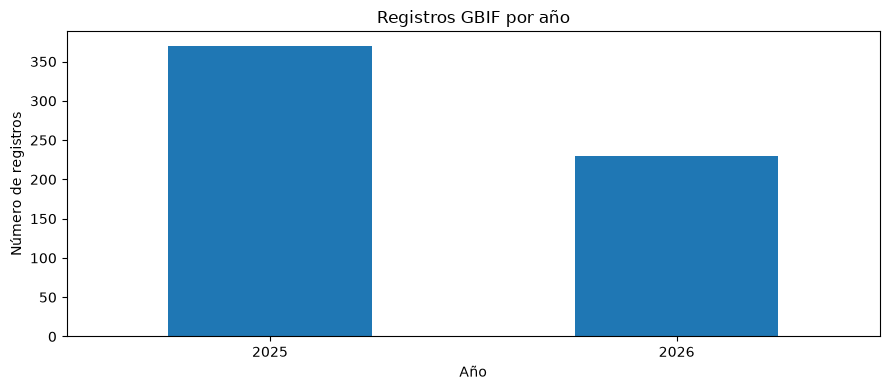

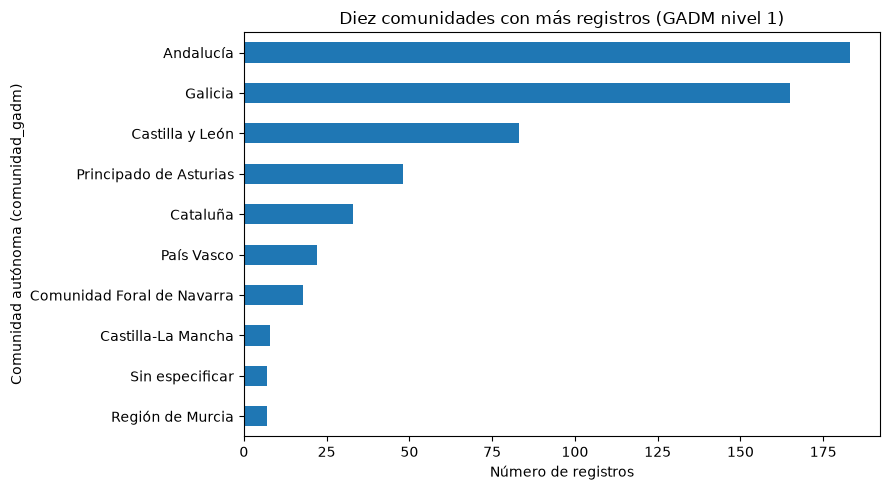

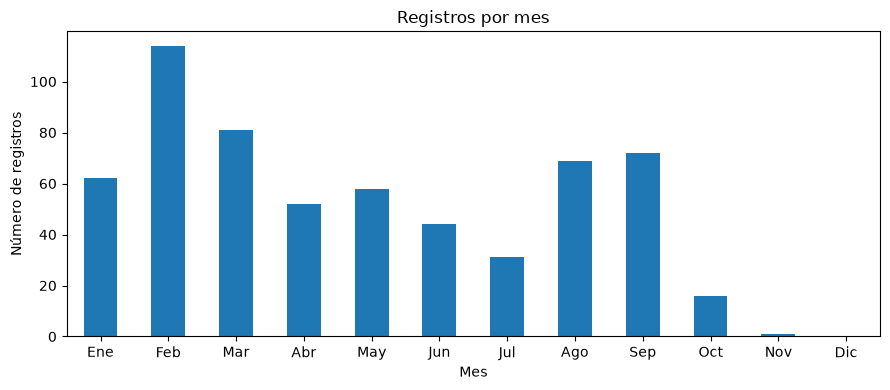

Conjunto limpio exportado a: registros_biodiversidad_gbif.csv


In [10]:
if not df.empty:
    # Evolución anual: el último año puede estar incompleto.
    registros_por_anio = df.dropna(subset=["year"]).groupby("year").size().sort_index()
    if not registros_por_anio.empty:
        ax = registros_por_anio.plot(kind="bar", figsize=(9, 4), title="Registros GBIF por año")
        ax.set_xlabel("Año")
        ax.set_ylabel("Número de registros")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    # Principales comunidades autónomas según GADM nivel 1 (normalizado).
    top_territorios = df["comunidad_gadm"].fillna("Sin especificar").value_counts().head(10).sort_values()
    if not top_territorios.empty:
        ax = top_territorios.plot(kind="barh", figsize=(9, 5), title="Diez comunidades con más registros (GADM nivel 1)")
        ax.set_xlabel("Número de registros")
        ax.set_ylabel("Comunidad autónoma (comunidad_gadm)")
        plt.tight_layout()
        plt.show()

    # Distribución mensual, cuando el campo month está informado.
    registros_por_mes = df.dropna(subset=["month"]).groupby("month").size().reindex(range(1, 13), fill_value=0)
    if registros_por_mes.sum() > 0:
        ax = registros_por_mes.plot(kind="bar", figsize=(9, 4), title="Registros por mes")
        ax.set_xlabel("Mes")
        ax.set_ylabel("Número de registros")
        plt.xticks(range(12), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"], rotation=0)
        plt.tight_layout()
        plt.show()

    ruta_csv = "registros_biodiversidad_gbif.csv"
    # Excluimos la columna 'issues' (lista) porque ya está serializada en 'issues_str'.
    df.drop(columns=["issues"], errors="ignore").to_csv(ruta_csv, index=False, encoding="utf-8-sig")
    print(f"Conjunto limpio exportado a: {ruta_csv}")
else:
    print("No se generan gráficos ni CSV porque no hay registros válidos.")

## 7. Mapa interactivo de registros con Folium

El mapa incorpora agrupación de marcadores (`MarkerCluster`) y dos mapas base:

- **CartoDB Positron:** fondo claro para distinguir los puntos.
- **OpenTopoMap:** relieve topográfico.

Los popups muestran campos disponibles y un enlace a la ficha del registro en GBIF. Los textos procedentes de la API se escapan antes de insertarlos en HTML.

El encuadre se ajusta a la extensión de los puntos mediante `fit_bounds()`. Si no hay datos válidos, se muestra un mapa de referencia de España sin intentar calcular medias de un DataFrame vacío.

In [11]:
# Si no hay registros, mostramos un mapa de referencia sin marcadores.
if df.empty:
    mapa = folium.Map(location=[40.2, -3.7], zoom_start=5, tiles="CartoDB positron")
    folium.LayerControl().add_to(mapa)
else:
    centro_lat = float(df["decimalLatitude"].median())
    centro_lon = float(df["decimalLongitude"].median())
    mapa = folium.Map(location=[centro_lat, centro_lon], zoom_start=6, tiles="CartoDB positron")

    folium.TileLayer(
        tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
        attr="Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)",
        name="Relieve topográfico (OpenTopoMap)",
        overlay=False,
        control=True,
    ).add_to(mapa)

    cluster = MarkerCluster(name="Registros de Canis lupus").add_to(mapa)

    for fila in df.itertuples(index=False):
        taxon_aceptado = html.escape(str(fila.acceptedScientificName)) if pd.notna(fila.acceptedScientificName) else html.escape(nombre_oficial)
        epiteto = html.escape(str(fila.specificEpithet)) if pd.notna(fila.specificEpithet) else "No disponible"
        fecha = html.escape(str(fila.eventDate)) if pd.notna(fila.eventDate) else "No disponible"
        comunidad = html.escape(str(fila.comunidad_gadm)) if pd.notna(fila.comunidad_gadm) else (html.escape(str(fila.stateProvince)) if pd.notna(fila.stateProvince) else "No especificado")
        provincia = html.escape(str(fila.provincia_gadm)) if pd.notna(fila.provincia_gadm) else "No especificada"
        vitalidad = html.escape(str(fila.vitality)) if pd.notna(fila.vitality) else "No informada"
        institucion = html.escape(str(fila.institutionCode)) if pd.notna(fila.institutionCode) else "No especificada"
        gbif_id = html.escape(str(fila.key)) if pd.notna(fila.key) else ""
        tipo = html.escape(str(fila.basisOfRecord)) if pd.notna(fila.basisOfRecord) else "No especificado"
        color_punto = "#1b4332" if fila.specificEpithet == "lupus" else "#b5651d"

        popup_html = f"""
        <div style="font-family: sans-serif; font-size: 13px; min-width: 220px;">
            <b><i>{taxon_aceptado}</i></b> (<code>{epiteto}</code>)<hr style="margin: 4px 0;">
            <b>Fecha:</b> {fecha}<br>
            <b>Territorio (GADM):</b> {comunidad} ({provincia})<br>
            <b>Vitalidad:</b> {vitalidad}<br>
            <b>Tipo de registro:</b> {tipo}<br>
            <b>Institución:</b> {institucion}<br>
            <a href="https://www.gbif.org/occurrence/{gbif_id}" target="_blank" rel="noopener noreferrer">Ver ficha en GBIF</a>
        </div>
        """

        folium.CircleMarker(
            location=[fila.decimalLatitude, fila.decimalLongitude],
            radius=5,
            color=color_punto,
            fill=True,
            fill_color=color_punto,
            fill_opacity=0.85,
            popup=folium.Popup(popup_html, max_width=280),
            tooltip=f"{epiteto} | {comunidad} ({provincia})",
        ).add_to(cluster)

    # Ajustamos el encuadre a todos los registros, evitando depender de la media.
    limites = [
        [float(df["decimalLatitude"].min()), float(df["decimalLongitude"].min())],
        [float(df["decimalLatitude"].max()), float(df["decimalLongitude"].max())],
    ]
    mapa.fit_bounds(limites)
    folium.LayerControl().add_to(mapa)

ruta_mapa = "mapa_avistamientos_gbif.html"
mapa.save(ruta_mapa)
print(f"Mapa guardado en: {ruta_mapa}")
mapa

c:\Users\chuwi\Documents\biodiversidad\.venv\Lib\site-packages\folium\raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Mapa guardado en: mapa_avistamientos_gbif.html


## 8. Lectura responsable de los resultados y posibles ampliaciones

- El recuento representa **registros** de GBIF, no individuos ni tamaño poblacional.
- `stateProvince` contiene el valor territorial suministrado por la fuente; no siempre equivale a una comunidad autónoma.
- `basisOfRecord` es una categoría Darwin Core, no una descripción completa del método de observación.
- El año 2026 no está completo; evita compararlo directamente con años completos.
- La descarga está limitada por `MAX_REGISTROS`; consulta `total_disponible_gbif` para conocer el total que GBIF indica para esos filtros.

Como ampliaciones, se pueden comparar periodos equivalentes, permitir filtros configurables, añadir capas por año o tipo de registro y estudiar la incertidumbre espacial. Para inferir tendencias poblacionales harían falta datos y métodos específicos, no solo recuentos brutos de ocurrencias.

Para consultar la definición exacta, cobertura y origen de cada campo del conjunto de datos, revisa [`diccionario_datos_gbif.md`](./docs/diccionario_datos_gbif.md).